# 📘 15 — ML: Regularization, Classification & Clustering
*Part of the Full Stack Data Science & AI booklet. Run cells top to bottom (Shift + Enter). Install libraries first: `pip install -r ../requirements.txt`.*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os, sys, math, random, json, time, copy, warnings
from IPython.display import display
warnings.filterwarnings("ignore")

In [2]:
# ---- Setup carried over from topic 14 so this notebook runs on its own ----
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
hs = pd.get_dummies(pd.read_csv("data/houses.csv"), columns=["location"], drop_first=True)   # house data, encoded
num_cols, cat_cols = ["age", "fare", "pclass"], ["sex", "embarked"]
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
_sal = pd.read_csv("data/Salary_Data.csv")
regressor = LinearRegression().fit(_sal[["YearsExperience"]], _sal["Salary"])             # salary model from topic 14

## 15.5 Overfitting, underfitting & Regularization
- **Underfitting**: model too simple (high bias). **Overfitting**: memorises noise (high variance) — great on train, bad on test.
- **Regularization** adds a penalty on big weights to keep the model simple.

| Method | Penalty | Effect |
|---|---|---|
| **Ridge (L2)** | α·Σw² | shrinks weights, keeps all features |
| **Lasso (L1)** | α·Σ\|w\| | can make weights exactly 0 → feature selection |
| **ElasticNet** | mix of both | balance |

In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import cross_val_score, GridSearchCV

# Overfit demo: a degree-12 polynomial on tiny noisy data
np.random.seed(3)
xs = np.sort(np.random.rand(30)); ys = np.sin(2 * np.pi * xs) + np.random.randn(30) * 0.3
Xp = xs.reshape(-1, 1); Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, ys, test_size=0.4, random_state=1)
for name, reg in [("Plain LinearReg", LinearRegression()), ("Ridge(α=0.01)", Ridge(alpha=.01)), ("Lasso(α=0.01)", Lasso(alpha=.01, max_iter=50000))]:
    pipe = Pipeline([("poly", PolynomialFeatures(12)), ("scale", StandardScaler()), ("reg", reg)]).fit(Xp_tr, yp_tr)
    print(f"{name:16} train R²={pipe.score(Xp_tr, yp_tr):.2f}  test R²={pipe.score(Xp_te, yp_te):.2f}")

# On house data: Ridge / Lasso / ElasticNet with scaling
X, y = hs.drop(columns="price_lakhs"), hs["price_lakhs"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=1)
for name, reg in [("Linear", LinearRegression()), ("Ridge", Ridge(alpha=10)), ("Lasso", Lasso(alpha=0.5)), ("ElasticNet", ElasticNet(alpha=0.5, l1_ratio=.5))]:
    p_ = Pipeline([("scale", StandardScaler()), ("m", reg)]).fit(Xtr, ytr)
    print(f"{name:10} R²={p_.score(Xte, yte):.3f}  weights={np.round(p_['m'].coef_, 2)}")   # Lasso zeroes weak features

# Choose alpha automatically with cross-validation
gs = GridSearchCV(Pipeline([("scale", StandardScaler()), ("m", Ridge())]), {"m__alpha": [0.01, 0.1, 1, 10, 100]}, cv=5).fit(Xtr, ytr)
print("Best alpha:", gs.best_params_, "CV R²:", round(gs.best_score_, 3))
print("5-fold CV scores:", cross_val_score(LinearRegression(), X, y, cv=5).round(3))

Plain LinearReg  train R²=0.92  test R²=-3.02
Ridge(α=0.01)    train R²=0.84  test R²=0.74
Lasso(α=0.01)    train R²=0.67  test R²=0.52
Linear     R²=0.935  weights=[38.55 11.39 -7.6  -8.64  1.21  1.37]
Ridge      R²=0.933  weights=[36.94 10.73 -7.3  -8.44  1.14  1.12]
Lasso      R²=0.937  weights=[38.01 10.85 -7.06 -8.11  0.04  0.14]
ElasticNet R²=0.889  weights=[30.38  8.04 -5.91 -7.31  0.59  0.  ]
Best alpha: {'m__alpha': 1} CV R²: 0.936
5-fold CV scores: [0.945 0.944 0.941 0.941 0.914]


#### 🔍 How it works
- The **degree-12 polynomial** has 13 weights for 18 training points: plain `LinearRegression` memorises noise → **train R² high, test R² poor** (overfitting). Ridge/Lasso penalise big weights → test score improves.
- `GridSearchCV(pipeline, {"m__alpha": [...]}, cv=5)` tries every alpha, scoring each with **5-fold cross-validation** (train on 4 parts, test on the 5th, rotate), then keeps the best. `m__alpha` = "parameter `alpha` of the pipeline step named `m`".
- `cross_val_score` gives 5 scores → their **spread** tells you how stable the model is.

## 15.5b Ridge & Lasso on the `car-mpg` dataset (class code, explained)
**Goal:** predict fuel efficiency `mpg` from engine and car features. **Problems in this data:** `car_name` is useless text, `origin` is a code (1/2/3) not a number, `hp` has `'?'` for missing → must clean first.

(398, 10)
Missing (NaN): 0 | '?' in hp: 6
Clean: 0 missing; (398, 11)
(278, 10) (120, 10) (278, 1) (120, 1)
The coef for cyl is -0.077
The coef for disp is 0.032
The coef for hp is -0.236
The coef for wt is -0.536
The coef for acc is 0.036
The coef for yr is 0.291
The coef for car_type is 0.042
The coef for origin_america is 0.023
The coef for origin_asia is 0.006
The coef for origin_europe is -0.036
The intercept is 0.0059

Ridge coef: [-0.076  0.026 -0.235 -0.531  0.037  0.29   0.042  0.023  0.006 -0.036]
Lasso coef: [-0.124 -0.    -0.192 -0.454  0.     0.203  0.     0.    -0.    -0.   ] <- some weights are exactly 0 = features removed
Linear  train R² = 0.838 | test R² = 0.819
Ridge   train R² = 0.838 | test R² = 0.818
Lasso   train R² = 0.814 | test R² = 0.784


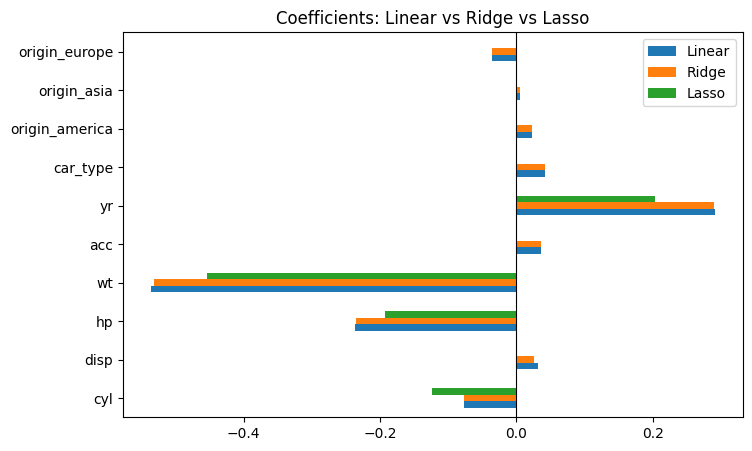

In [4]:
from sklearn import preprocessing
from sklearn.linear_model import LinearRegression, Ridge, Lasso
data = pd.read_csv("data/car-mpg.csv")
print(data.shape); print("Missing (NaN):", data.isnull().sum().sum(), "| '?' in hp:", (data.hp.astype(str) == "?").sum())

data = data.drop(["car_name"], axis=1)                                          # 1) drop unhelpful column
data["origin"] = data["origin"].replace({1: "america", 2: "europe", 3: "asia"}) # 2) numbers -> real labels
data = pd.get_dummies(data, columns=["origin"], dtype=int)                      # 3) one-hot encode
data = data.replace("?", np.nan)                                                # 4) '?' -> proper missing value
data["hp"] = pd.to_numeric(data["hp"])                                          # 5) text column -> numbers
data = data.fillna(data.median(numeric_only=True))                              # 6) fill missing with median
print("Clean:", data.isnull().sum().sum(), "missing;", data.shape)

x = data.drop(["mpg"], axis=1); y = data[["mpg"]]
x_s = pd.DataFrame(preprocessing.scale(x), columns=x.columns)                   # 7) standardise: mean 0, std 1
y_s = preprocessing.scale(y)
x_train, x_test, y_train, y_test = train_test_split(x_s, y_s, test_size=0.3, random_state=0)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

regression_model = LinearRegression().fit(x_train, y_train)
for idx, col_name in enumerate(x_train.columns):
    print("The coef for {} is {:.3f}".format(col_name, regression_model.coef_[0][idx]))
print("The intercept is {:.4f}".format(regression_model.intercept_[0]))

ridge_model = Ridge(alpha=0.3).fit(x_train, y_train)
lasso_model = Lasso(alpha=0.1).fit(x_train, y_train)
print("\nRidge coef:", ridge_model.coef_.round(3).ravel())
print("Lasso coef:", lasso_model.coef_.round(3), "<- some weights are exactly 0 = features removed")
for name, mdl in [("Linear", regression_model), ("Ridge", ridge_model), ("Lasso", lasso_model)]:
    print(f"{name:7} train R² = {mdl.score(x_train, y_train):.3f} | test R² = {mdl.score(x_test, y_test):.3f}")

# Visualise how coefficients shrink
coefs = pd.DataFrame({"Linear": regression_model.coef_[0], "Ridge": ridge_model.coef_.ravel(), "Lasso": lasso_model.coef_}, index=x.columns)
coefs.plot.barh(figsize=(8, 5), title="Coefficients: Linear vs Ridge vs Lasso"); plt.axvline(0, color="k", lw=.8); plt.show()

#### 🔍 How it works (step by step)
1. `drop(["car_name"], axis=1)` → remove an identifier; a name has no predictive meaning.
2. `.replace({1:'america',...})` → codes → readable labels (so we don't treat 3 as "bigger" than 1).
3. `get_dummies` → one 0/1 column per category (**one-hot encoding**); ML models need numbers.
4. `.replace('?', np.nan)` + `pd.to_numeric` → a column with `'?'` is read as text; this makes it numeric with true NaN.
5. `fillna(median)` → median ignores outliers (better than mean for skewed data like horsepower).
6. `preprocessing.scale` → **standardisation** `(x − mean) / std`. Required for Ridge/Lasso because the penalty treats all weights equally, so features must be on the same scale (weight in kg vs. cylinders would otherwise dominate).
7. **Ridge (L2)** adds `α × Σ(weight²)` to the loss → shrinks all weights smoothly. **Lasso (L1)** adds `α × Σ|weight|` → pushes weak weights to **exactly 0** (automatic feature selection). Bigger `alpha` = stronger penalty.
8. Compare **train vs test R²**: regularization helps when linear regression overfits (train ≫ test).
> ⚠️ *Professional note:* the class code scales **before** splitting (mild data leakage, because test statistics leak into scaling). Production code scales **after** splitting using a `Pipeline`, as shown earlier in 15.1.
#### 💼 Where it's used
Models with **many correlated features** (finance, genomics, text): Lasso picks the useful ones, Ridge stabilises estimates. Also the base idea behind weight decay in deep learning.

## 15.6 Classification: Logistic Regression, KNN, Trees, Random Forest
**Logistic regression** predicts a *probability* (0–1) using the sigmoid curve, then thresholds it (usually 0.5).
**Classification metrics**: Accuracy, Precision (of predicted positives, how many are right), Recall (of real positives, how many found), F1 (balance), Confusion matrix, ROC-AUC.

Logistic       accuracy=0.720  AUC=0.803
KNN(k=7)       accuracy=0.680  AUC=0.732
Tree(depth 4)  accuracy=0.690  AUC=0.714


RandomForest   accuracy=0.690  AUC=0.738
              precision    recall  f1-score   support

           0       0.72      0.74      0.73        57
           1       0.64      0.63      0.64        43

    accuracy                           0.69       100
   macro avg       0.68      0.68      0.68       100
weighted avg       0.69      0.69      0.69       100



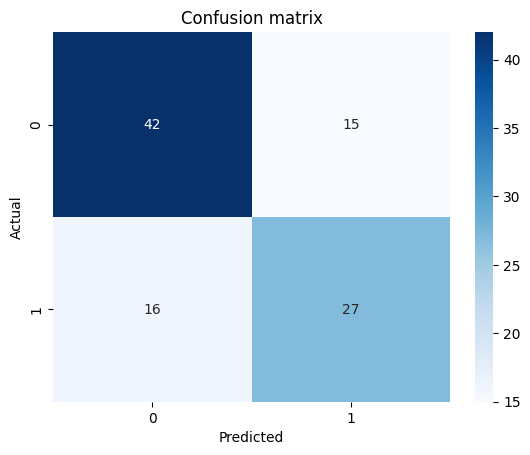

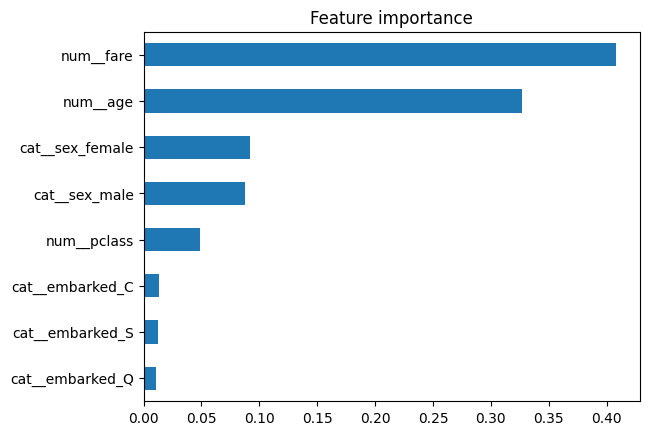

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

pas = pd.read_csv("data/passengers.csv")
X, y = pas.drop(columns="survived"), pas["survived"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {"Logistic": LogisticRegression(max_iter=1000), "KNN(k=7)": KNeighborsClassifier(7),
          "Tree(depth 4)": DecisionTreeClassifier(max_depth=4, random_state=0), "RandomForest": RandomForestClassifier(200, random_state=0)}
results = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)]).fit(Xtr, ytr)
    pr = pipe.predict(Xte); results[name] = pipe
    print(f"{name:14} accuracy={accuracy_score(yte, pr):.3f}  AUC={roc_auc_score(yte, pipe.predict_proba(Xte)[:, 1]):.3f}")

best = results["RandomForest"]
print(classification_report(yte, best.predict(Xte)))
sns.heatmap(confusion_matrix(yte, best.predict(Xte)), annot=True, fmt="d", cmap="Blues"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix"); plt.show()
imp = pd.Series(best["clf"].feature_importances_, index=best["prep"].get_feature_names_out()).sort_values()
imp.plot.barh(title="Feature importance"); plt.show()

#### 🔍 How it works
- **Logistic regression** → probability via the sigmoid curve; **KNN** → votes of the k closest points; **Decision tree** → a chain of yes/no questions; **Random forest** → 200 trees voting (reduces overfitting).
- **Metrics:** *Accuracy* = correct ÷ all (misleading when classes are imbalanced). *Precision* = of predicted positives, how many were right. *Recall* = of real positives, how many we found. *F1* = balance of both. *AUC* = how well the model ranks positives above negatives (0.5 = random, 1 = perfect).
- **Confusion matrix:** rows = actual, columns = predicted; the diagonal = correct. `feature_importances_` shows which inputs the forest used most.
#### 💼 Where it's used
Fraud detection, churn prediction, spam filtering, medical screening. In fraud, **recall** matters more than accuracy (missing fraud is costly).

## 15.7 Unsupervised: K-Means clustering & PCA

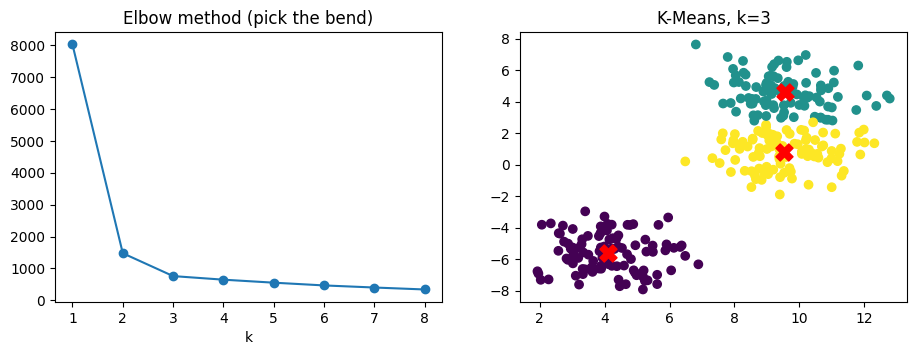

PCA variance explained: [0.262 0.192]


In [6]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs

Xb, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.2, random_state=4)
inertia = [KMeans(k, n_init=10, random_state=0).fit(Xb).inertia_ for k in range(1, 9)]
km = KMeans(3, n_init=10, random_state=0).fit(Xb)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(range(1, 9), inertia, "o-"); ax[0].set_title("Elbow method (pick the bend)"); ax[0].set_xlabel("k")
ax[1].scatter(Xb[:, 0], Xb[:, 1], c=km.labels_, cmap="viridis"); ax[1].scatter(*km.cluster_centers_.T, c="red", marker="X", s=150); ax[1].set_title("K-Means, k=3")
plt.show()

pca = PCA(n_components=2).fit(StandardScaler().fit_transform(hs.drop(columns="price_lakhs").astype(float)))
print("PCA variance explained:", pca.explained_variance_ratio_.round(3))

#### 🔍 How it works
- **K-Means:** pick k centres → assign each point to the nearest → move centres to the mean of their points → repeat until stable. **Elbow plot:** inertia (total distance to centres) vs k; pick the k where the curve bends.
- **PCA:** rotates the data to new axes that capture the most variance; `explained_variance_ratio_` shows how much information each component keeps → used to **reduce dimensions** and visualise.
#### 💼 Where it's used
Customer segmentation, image compression, anomaly detection, speeding up models.

## 15.8 Save & load a model

In [7]:
import joblib
joblib.dump(best, "titanic_model.pkl")
loaded = joblib.load("titanic_model.pkl")
new_person = pd.DataFrame([{"pclass": 1, "sex": "female", "age": 28, "fare": 80.0, "embarked": "S"}])
print("Survival probability:", loaded.predict_proba(new_person)[0, 1].round(3))

Survival probability: 0.855


#### 🔍 How it works
- `joblib.dump(pipeline, file)` saves the **whole pipeline** (preprocessing + model) to disk. `load` restores it in another script or server. `predict_proba` gives the probability, not just the class.
- Saving the pipeline (not just the model) guarantees new data gets the same cleaning.

### pickle vs joblib — saving a trained model
| | `pickle` | `joblib` |
|---|---|---|
| Part of | Python standard library | scikit-learn ecosystem |
| Best for | any Python object | models holding large NumPy arrays (faster, compressed) |
| Code | `pickle.dump(obj, f)` / `pickle.load(f)` | `joblib.dump(obj, path)` / `joblib.load(path)` |
> ⚠️ **Security:** never load a pickle/joblib file from someone you don't trust — it can run code when loaded.

In [8]:
import pickle
with open("linear_regression_model.pkl", "wb") as file:      # 'wb' = write in binary mode
    pickle.dump(regressor, file)                              # regressor = the Salary model from 15.2b
print("Model pickled -> linear_regression_model.pkl")
with open("linear_regression_model.pkl", "rb") as file:      # 'rb' = read binary
    reloaded = pickle.load(file)
print("Reloaded prediction for 5 years:", reloaded.predict(pd.DataFrame({"YearsExperience": [5]}))[0].round(0))
import os; print("Saved in folder:", os.getcwd())

Model pickled -> linear_regression_model.pkl
Reloaded prediction for 5 years: 73042.0
Saved in folder: .


## 🚀 Mini Project 10: House Price Predictor (end-to-end)
Combine everything: load → clean → EDA → features → model → evaluate → save → predict.

In [9]:
hs = pd.read_csv("data/houses.csv")
X, y = hs.drop(columns="price_lakhs"), hs["price_lakhs"]
pre = ColumnTransformer([("num", StandardScaler(), ["area_sqft", "bedrooms", "age_years", "dist_city_km"]),
                         ("cat", OneHotEncoder(drop="first"), ["location"])])
pipe = Pipeline([("pre", pre), ("model", Ridge(alpha=1))])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=7)
pipe.fit(Xtr, ytr)
print(f"Test R²: {pipe.score(Xte, yte):.3f} | RMSE: {mean_squared_error(yte, pipe.predict(Xte))**.5:.2f} lakhs")
joblib.dump(pipe, "house_model.pkl")

def predict_price(area, beds, age, dist, loc):
    row = pd.DataFrame([{"area_sqft": area, "bedrooms": beds, "age_years": age, "dist_city_km": dist, "location": loc}])
    return round(float(pipe.predict(row)[0]), 1)
print("🏠 1500 sqft, 3 BHK, 5 yrs old, 8 km away ->", predict_price(1500, 3, 5, 8, "Urban"), "lakhs")

Test R²: 0.945 | RMSE: 10.63 lakhs
🏠 1500 sqft, 3 BHK, 5 yrs old, 8 km away -> 96.9 lakhs


#### 🔍 How it works
- One `Pipeline` = `ColumnTransformer` (scale numbers, one-hot the location) + `Ridge`. `predict_price()` wraps it so anyone can call it with plain values.
- This is the **full ML lifecycle** in 15 lines: data → split → pipeline → train → score → save → serve.
#### 💼 Where it's used
Property portals, insurance quotes, price estimators — all follow this structure.

### 🧪 Practice (Section 15)
1. Predict `marks` from all columns of students.csv. 2. Compare Ridge vs Lasso on houses. 3. Change the learning rate in gradient descent and plot. 4. Improve passenger model using GridSearchCV on RandomForest.